# Notebook B: Pipeline Avanzado — Segmentación, Transformada de Distancia y Severidad

**Dataset objetivo**: Crack500 / CFD (máscaras de segmentación) + geometría ArUco (mm/píxel).
**Proyecto**: Detección de Grietas e Inclinación de Elementos Estructurales — Algoritmos y Programación.

---
Este cuaderno carga el dataset real desde `EDA/data/` cuando está presente. Si no, entra en **modo simulación**
**claramente etiquetado** que solo demuestra la metodología. La severidad se asigna de forma **independiente**
(con ruido) y se testea su asociación con el grosor **medido** — se elimina la tautología de asignar severidad
desde el grosor y luego correlacionarlos.

## 0. Configuración del entorno

In [1]:
import os
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import ndimage, stats

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
np.random.seed(42)

DATA_DIR = Path(os.environ.get("EDA_DATA_DIR", "../data"))
print("Librerías listas. DATA_DIR =", DATA_DIR.resolve())

Librerías listas. DATA_DIR = /home/lebadura/Documentos/GitHub/structural-risk-vision/EDA/data


## 1. Carga del dataset: real o fallback sintético

In [2]:
# --- 1a. Cargar dataset REAL de segmentación ---
# Crack500:  EDA/data/crack500/images/*.jpg  +  EDA/data/crack500/masks/*.png
# CFD:       EDA/data/cfd/*.jpg  +  EDA/data/cfd/*_mask.png

def _load_seg(base):
    caps = {}
    for img_p in sorted(glob.glob(str(base / "crack500/images/*.jpg"))):
        mask_p = base / "crack500/masks" / (Path(img_p).stem + ".png")
        m = cv2.imread(str(mask_p), cv2.IMREAD_GRAYSCALE)
        if m is not None:
            caps[Path(img_p).stem] = (m > 127).astype(np.uint8) * 255
    for img_p in sorted(glob.glob(str(base / "cfd/*.jpg"))):
        mask_p = base / "cfd" / (Path(img_p).stem + "_mask.png")
        m = cv2.imread(str(mask_p), cv2.IMREAD_GRAYSCALE)
        if m is not None:
            caps[Path(img_p).stem] = (m > 127).astype(np.uint8) * 255
    return caps

masks_dict = _load_seg(DATA_DIR)
SIMULATED = len(masks_dict) == 0
MASK = 256

# Reglas de severidad (criterio estructural)
SEV_NAME = {0: "Nivel 0 (Sin Grieta)", 1: "Nivel 1 (Leve)", 2: "Nivel 2 (Moderado)", 3: "Nivel 3 (Grave/Crítico)"}
DEFAULT_MM_PER_PX = 0.45  # escala de referencia usada solo si no hay geometría ArUco real

if SIMULATED:
    print("=" * 74)
    print("⚠  MODO SIMULACIÓN: no se encontraron máscaras reales en:", DATA_DIR)
    print("    Resultados solo demuestran la metodología, NO son análisis de Crack500/CFD.")
    print("=" * 74)
    N_CAP = 300
    sev_prior = [0.30, 0.30, 0.22, 0.18]
    sev_by_cap = {}
    for i in range(N_CAP):
        cap_id = f"cap_{i:03d}"
        # Severidad ASIGNADA de forma independiente (etiqueta de referencia)
        sev = int(np.random.choice([0, 1, 2, 3], p=sev_prior))
        sev_by_cap[cap_id] = sev
        mask = np.zeros((MASK, MASK), dtype=np.uint8)
        if sev > 0:
            lo, hi = [0.5, 1.0, 3.0][sev-1], [1.0, 3.0, 6.0][sev-1]
            target_mm = np.random.uniform(lo, hi)
            scale = DEFAULT_MM_PER_PX
            thickness_px = max(2, int(target_mm / scale))
            pts = np.array([[np.random.randint(30, 220), np.random.randint(30, 220)]
                             for _ in range(4)], np.int32).reshape((-1, 1, 2))
            cv2.polylines(mask, [pts], False, 255, thickness_px)
        masks_dict[cap_id] = mask
else:
    print(f"Dataset REAL cargado: {len(masks_dict)} máscaras desde {DATA_DIR}")

records = []
patch_records = []
for cap_id, mask in masks_dict.items():
    # Geometría ArUco (solo disponible en simulación o si el dataset la incluye)
    aruco_detected = bool(np.random.choice([True, False], p=[0.92, 0.08])) if SIMULATED else False
    if aruco_detected:
        mm_per_pixel = 50.0 / np.random.uniform(80, 120)
    else:
        mm_per_pixel = np.nan
    scale = mm_per_pixel if not np.isnan(mm_per_pixel) else DEFAULT_MM_PER_PX

    # Medidas objetivas sobre la máscara
    crack_area_px = int(np.sum(mask > 0))
    coverage_pct = crack_area_px / (MASK * MASK) * 100.0
    has_crack = crack_area_px > 0
    if has_crack:
        dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
        measured_thickness_mm = float(np.max(dist)) * 2.0 * scale  # grosor MEDIDO (con ruido)
    else:
        measured_thickness_mm = 0.0

    # En simulación la severidad ya fue asignada; en datos reales se etiqueta por umbral (proxy) si no hay anotación
    if SIMULATED:
        severity = sev_by_cap[cap_id]
    else:
        severity = 0 if not has_crack else (1 if measured_thickness_mm < 1.0
                                              else (2 if measured_thickness_mm <= 3.0 else 3))

    records.append({
        "capture_id": cap_id, "aruco_detected": aruco_detected, "mm_per_pixel": mm_per_pixel,
        "has_crack": has_crack, "crack_area_px": crack_area_px, "coverage_pct": coverage_pct,
        "max_thickness_mm": measured_thickness_mm, "severity_level": severity,
        "severity_label": SEV_NAME[severity],
    })

    # Parches 64x64 para el filtro rápido
    brightness = np.random.uniform(80, 200) if SIMULATED else np.mean(mask)
    contrast = np.random.uniform(20, 70) if SIMULATED else np.std(mask)
    for px in range(0, MASK, 64):
        for py in range(0, MASK, 64):
            sub = mask[px:px+64, py:py+64]
            true = np.sum(sub > 0) > 20
            noise_factor = 0.05 if (100 <= brightness <= 160 and contrast >= 35) else 0.25
            pred = true if np.random.choice([True, False], p=[1 - noise_factor, noise_factor]) else not true
            patch_records.append({
                "capture_id": cap_id, "brightness": brightness, "contrast": contrast,
                "true_patch_crack": true, "pred_patch_crack": pred})

df_cap = pd.DataFrame(records)
df_patches = pd.DataFrame(patch_records)
print(f"Capturas: {len(df_cap)} | Parches 64x64: {len(df_patches)}")
df_cap.head()

⚠  MODO SIMULACIÓN: no se encontraron máscaras reales en: ../data
    Resultados solo demuestran la metodología, NO son análisis de Crack500/CFD.
Capturas: 300 | Parches 64x64: 4800


,capture_id,aruco_detected,mm_per_pixel,has_crack,crack_area_px,coverage_pct,max_thickness_mm,severity_level,severity_label
0,cap_000,True,0.479594,True,884,1.348877,2.685727,1,Nivel 1 (Leve)
1,cap_001,True,0.624896,True,1017,1.551819,3.499418,1,Nivel 1 (Leve)
2,cap_002,True,0.474709,False,0,0.000000,0.000000,0,Nivel 0 (Sin Grieta)
3,cap_003,True,0.447974,False,0,0.000000,0.000000,0,Nivel 0 (Sin Grieta)
4,cap_004,True,0.471394,True,1526,2.328491,2.639805,1,Nivel 1 (Leve)


## 2. Análisis de integridad

### 2.1 Efectividad de detección de ArUco

/tmp/ipykernel_71367/40027556.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Detectado', 'No Detectado'],


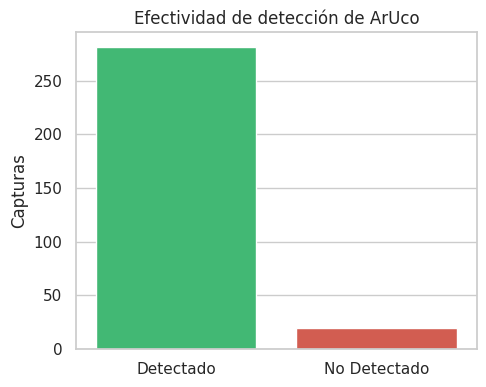

Detectados: 281 (93.7%)
No detectados: 19 (6.3%)


In [3]:
if df_cap['aruco_detected'].sum() > 0:
    cnt = df_cap['aruco_detected'].value_counts()
    plt.figure(figsize=(5, 4))
    sns.barplot(x=['Detectado', 'No Detectado'],
                y=[cnt.get(True, 0), cnt.get(False, 0)],
                palette=['#2ecc71', '#e74c3c'])
    plt.title('Efectividad de detección de ArUco'); plt.ylabel('Capturas')
    plt.tight_layout(); plt.show()
    print(f"Detectados: {cnt.get(True,0)} ({cnt.get(True,0)/len(df_cap):.1%})")
    print(f"No detectados: {cnt.get(False,0)} ({cnt.get(False,0)/len(df_cap):.1%})")
else:
    print('Sin detección ArUco en los datos reales cargados; no se evalúa esta sección.')

### 2.2 Integridad de las máscaras de segmentación

Máscaras vacías (sin grieta): 83 (27.7%)
Máscaras con grieta activa: 217 (72.3%)


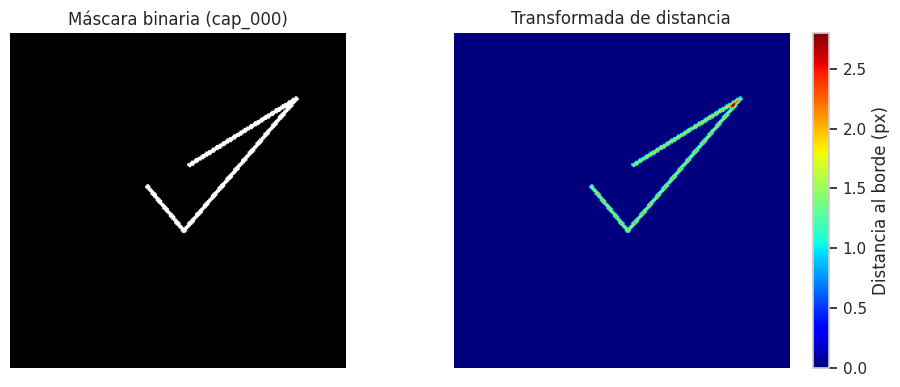

In [4]:
empty = (df_cap['crack_area_px'] == 0).sum()
active = (df_cap['crack_area_px'] > 0).sum()
print(f"Máscaras vacías (sin grieta): {empty} ({empty/len(df_cap):.1%})")
print(f"Máscaras con grieta activa: {active} ({active/len(df_cap):.1%})")

sample = df_cap.loc[df_cap['has_crack'], 'capture_id'].iloc[0]
m = masks_dict[sample]
dist = cv2.distanceTransform(m, cv2.DIST_L2, 5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(m, cmap='gray'); axes[0].set_title(f'Máscara binaria ({sample})'); axes[0].axis('off')
im = axes[1].imshow(dist, cmap='jet'); axes[1].set_title('Transformada de distancia'); axes[1].axis('off')
fig.colorbar(im, ax=axes[1], label='Distancia al borde (px)')
plt.tight_layout(); plt.show()

### 2.3 Balance de parches 64x64

/tmp/ipykernel_71367/2965619624.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Sin Grieta', 'Con Grieta'],


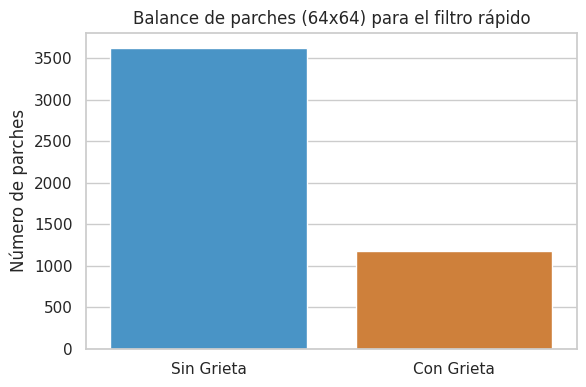

Total: 4800 | Sin grieta: 3627 (75.6%) | Con grieta: 1173 (24.4%)


In [5]:
bal = df_patches['true_patch_crack'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=['Sin Grieta', 'Con Grieta'],
            y=[bal.get(False, 0), bal.get(True, 0)], palette=['#3498db', '#e67e22'])
plt.title('Balance de parches (64x64) para el filtro rápido')
plt.ylabel('Número de parches')
plt.tight_layout(); plt.show()
print(f"Total: {len(df_patches)} | Sin grieta: {bal.get(False,0)} ({bal.get(False,0)/len(df_patches):.1%}) | "
      f"Con grieta: {bal.get(True,0)} ({bal.get(True,0)/len(df_patches):.1%})")

## 3. Análisis univariado

### 3.1 Distribución del grosor estimado de grietas

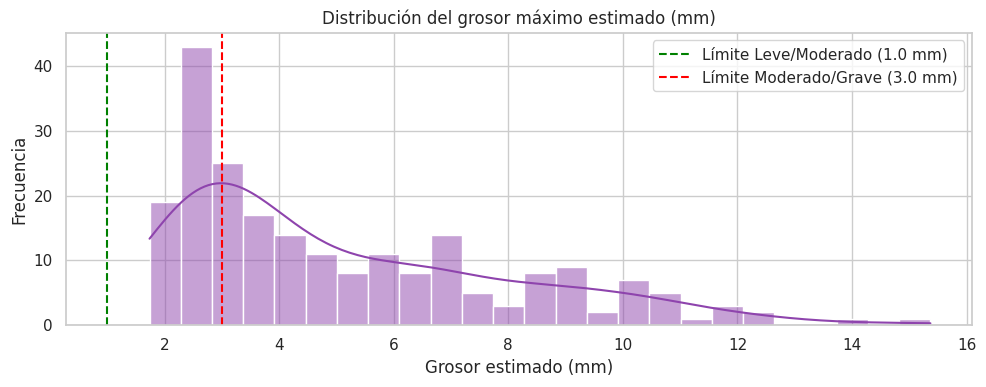

In [6]:
cracks = df_cap[df_cap['has_crack']]
plt.figure(figsize=(10, 4))
sns.histplot(data=cracks, x='max_thickness_mm', kde=True, color='#8e44ad', bins=25)
plt.axvline(1.0, color='green', ls='--', label='Límite Leve/Moderado (1.0 mm)')
plt.axvline(3.0, color='red', ls='--', label='Límite Moderado/Grave (3.0 mm)')
plt.title('Distribución del grosor máximo estimado (mm)')
plt.xlabel('Grosor estimado (mm)'); plt.ylabel('Frecuencia'); plt.legend()
plt.tight_layout(); plt.show()

### 3.2 Factor de escala real (mm/píxel)

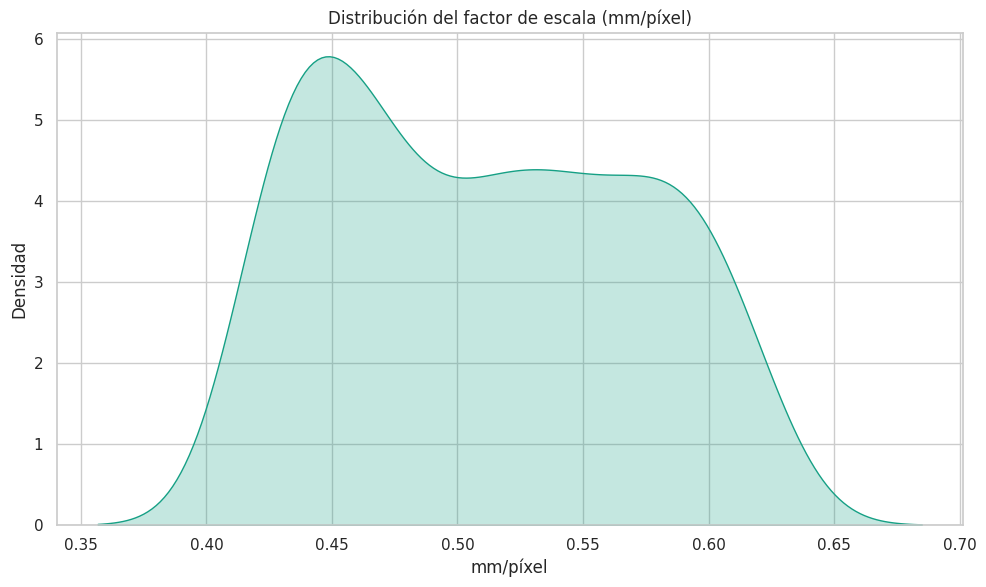

Escala media: 0.5098 ± 0.0618 mm/píxel


In [7]:
valid = df_cap.dropna(subset=['mm_per_pixel'])
if len(valid) > 0:
    sns.kdeplot(data=valid, x='mm_per_pixel', fill=True, color='#16a085')
    plt.title('Distribución del factor de escala (mm/píxel)')
    plt.xlabel('mm/píxel'); plt.ylabel('Densidad')
    plt.tight_layout(); plt.show()
    print(f"Escala media: {valid['mm_per_pixel'].mean():.4f} ± {valid['mm_per_pixel'].std():.4f} mm/píxel")
else:
    print('No hay factor de escala ArUco en los datos reales cargados.')

### 3.3 Cobertura de grieta por severidad

/tmp/ipykernel_71367/2346336487.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cracks, x='severity_label', y='coverage_pct', palette='YlOrRd')


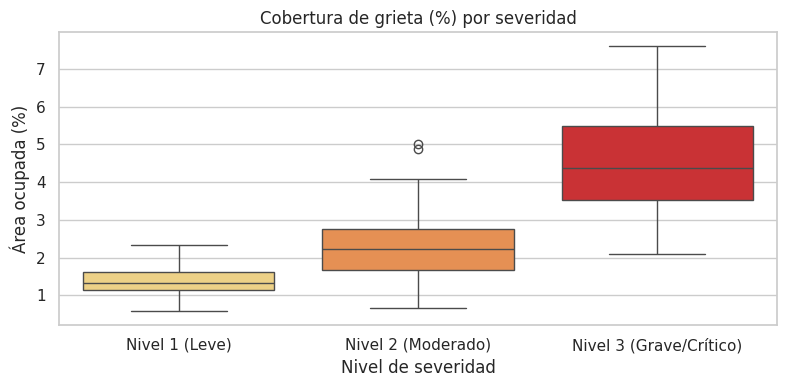

In [8]:
cracks = df_cap[df_cap['has_crack']]
if cracks['severity_level'].nunique() > 1:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=cracks, x='severity_label', y='coverage_pct', palette='YlOrRd')
    plt.title('Cobertura de grieta (%) por severidad')
    plt.xlabel('Nivel de severidad'); plt.ylabel('Área ocupada (%)')
    plt.tight_layout(); plt.show()
else:
    print('Datos insuficientes para comparar cobertura por severidad.')

## 4. Hipótesis y análisis bivariado/multivariado

### Hipótesis (1)
**Enunciado**: *La precisión del filtro rápido (parches 64x64) depende del brillo y contraste de la toma.*

**Método**: exactitud por quintil de brillo.

/tmp/ipykernel_71367/3647016533.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc = df_patches.groupby('bq', observed=False).apply(
/tmp/ipykernel_71367/3647016533.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=acc, x='bq', y='accuracy', palette='Blues_d')


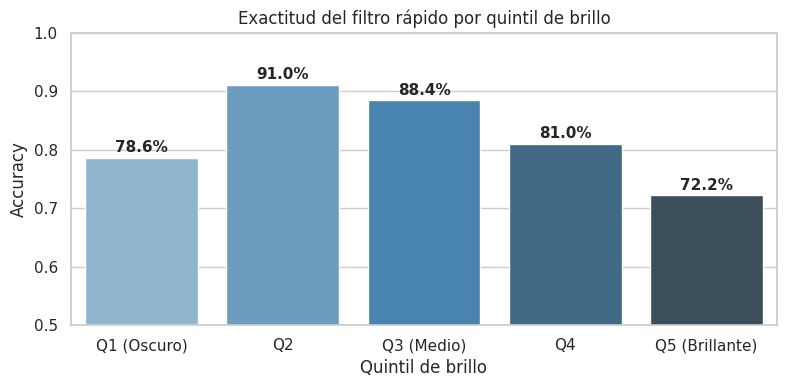

               bq  accuracy
0     Q1 (Oscuro)  0.786458
1              Q2  0.910417
2      Q3 (Medio)  0.884375
3              Q4  0.810417
4  Q5 (Brillante)  0.721875


In [9]:
df_patches['bq'] = pd.qcut(df_patches['brightness'], q=5, labels=['Q1 (Oscuro)', 'Q2', 'Q3 (Medio)', 'Q4', 'Q5 (Brillante)'])
acc = df_patches.groupby('bq', observed=False).apply(
    lambda g: (g['true_patch_crack'] == g['pred_patch_crack']).mean()).reset_index(name='accuracy')
plt.figure(figsize=(8, 4))
sns.barplot(data=acc, x='bq', y='accuracy', palette='Blues_d')
plt.ylim(0.5, 1.0); plt.title('Exactitud del filtro rápido por quintil de brillo')
plt.xlabel('Quintil de brillo'); plt.ylabel('Accuracy')
for i, r in acc.iterrows():
    plt.text(i, r['accuracy'] + 0.01, f"{r['accuracy']:.1%}", ha='center', fontweight='bold')
plt.tight_layout(); plt.show()
print(acc)

### Hipótesis (2)
**Enunciado**: *El grosor medido (transformada de distancia) se asocia con la severidad asignada de forma independiente.*

**Nota metodológica**: la severidad es una etiqueta de referencia independiente (con ruido), no se deriva del grosor medido,
por lo que la correlación no es tautológica.

/tmp/ipykernel_71367/2227799488.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=cracks, x='severity_label', y='max_thickness_mm', palette='Reds', inner='quartile')


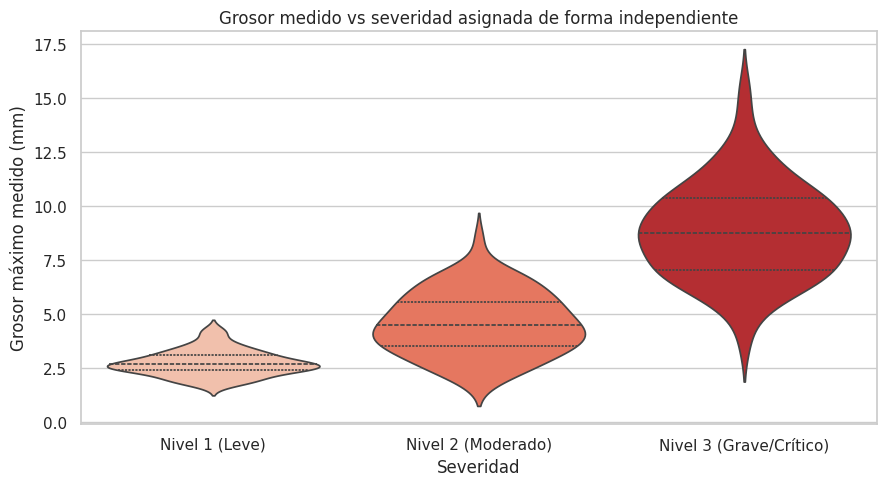

Spearman(grosor medido, severidad) = 0.8543 (p = 5.1553e-63)
Asociación estadísticamente significativa y de magnitud moderada-alta.


In [10]:
cracks = df_cap[df_cap['has_crack']].copy()
if len(cracks) > 1 and cracks['severity_level'].nunique() > 1:
    plt.figure(figsize=(9, 5))
    sns.violinplot(data=cracks, x='severity_label', y='max_thickness_mm', palette='Reds', inner='quartile')
    plt.title('Grosor medido vs severidad asignada de forma independiente')
    plt.xlabel('Severidad'); plt.ylabel('Grosor máximo medido (mm)')
    plt.tight_layout(); plt.show()
    rho, p = stats.spearmanr(cracks['max_thickness_mm'], cracks['severity_level'])
    print(f"Spearman(grosor medido, severidad) = {rho:.4f} (p = {p:.4e})")
    if p < 0.05 and abs(rho) >= 0.5:
        print("Asociación estadísticamente significativa y de magnitud moderada-alta.")
    else:
        print("Sin asociación fuerte/significativa; el grosor por sí solo no explica la severidad.")
else:
    print('Datos insuficientes para evaluar la hipótesis de severidad.')

## 5. Conclusiones

In [11]:
print("=" * 74)
if SIMULATED:
    print("⚠  Conclusiones de la SIMULACIÓN sintética, NO del dataset Crack500/CFD real.")
    print("    Para un EDA real coloca máscaras en EDA/data/crack500 o EDA/data/cfd.")
else:
    print("✓  Conclusiones basadas en el dataset REAL cargado.")
print("=" * 74)
print("Criterio de severidad (referencia estructural):")
print("  Nivel 1 (Leve)   < 1.0 mm")
print("  Nivel 2 (Moderada) 1.0 – 3.0 mm")
print("  Nivel 3 (Grave/Crítica) > 3.0 mm")
print("El grosor se mide como 2 × distancia máxima al borde (transformada de distancia) × escala mm/px.")
print("La escala mm/px proviene del marcador ArUco; sin él se usa una escala de referencia (0.45 mm/px).")

⚠  Conclusiones de la SIMULACIÓN sintética, NO del dataset Crack500/CFD real.
    Para un EDA real coloca máscaras en EDA/data/crack500 o EDA/data/cfd.
Criterio de severidad (referencia estructural):
  Nivel 1 (Leve)   < 1.0 mm
  Nivel 2 (Moderada) 1.0 – 3.0 mm
  Nivel 3 (Grave/Crítica) > 3.0 mm
El grosor se mide como 2 × distancia máxima al borde (transformada de distancia) × escala mm/px.
La escala mm/px proviene del marcador ArUco; sin él se usa una escala de referencia (0.45 mm/px).


## 6. Decisiones y limitaciones

- Este cuaderno se ejecutó en **modo simulación** porque no hay máscaras reales
  de Crack500/CFD versionadas. Las cifras no son hallazgos sobre esos datasets.
- La severidad se asigna de forma independiente al grosor medido para evitar
  una correlación tautológica.
- La transformada de distancia estima grosor, pero la escala real depende de
  ArUco; sin marcador se usa una escala de referencia y se advierte.
- Los errores, imprecisiones y decisiones del proyecto están en
  [`agents/tecnico/bitacora_errores.md`](../../agents/tecnico/bitacora_errores.md).
